## **Analysis Notebook**

#### **Major question**

> **Did India's economy become substantially larger between May 2004-May2014 and May 2014-May2024?**

When working with macroeconomic datasets, we need to understand these 7 core metrics to handle the vast majority of economic data task:

GDP Variations:
```text
1. GDP growth (annual%)
2. GDP (current US$/LCU) AKA (Nominal GDP)
3. GDP (constant US$/LCU) AKA (Real GDP)
4. GDP per capita
5. GDP, PPP (Purchasing Power Parity)
6. Inflation, GDP deflator
7. Compound Growth of real GDP - CAGR (Compound Annual Growth Rate)
```
Explainations for each terms will be held in "Terms_explaination.md" file.

#### **Required Modules**

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import os

#### **Subquestions**
1. **How did India's GDP change in absolute terms?**
- GDP at the beginning and end of each period
- Absolute increase in GDP
- Percentage increase in GDP
- How large was the economy at the end of each period?

let's find out each one....

#### **Data Ingestion**

In [2]:
# file path
file_path: str = 'Cleaned_datasets/Production/production_GDP_dataset.parquet'

if not os.path.exists(file_path):
    raise FileNotFoundError (f'{file_path} does not exist!')

try:
    df = pd.read_parquet(file_path)
    print(f'Successfully Loaded the file containing {len(df)} number of rows')
except Exception as e:
    print(f'Failed to read parquet file: {file_path}')
    raise

Successfully Loaded the file containing 21 number of rows


In [40]:
df

,Year,Inflation(annual %),GDP_Current(US$ Trillion),GDP_Constant(2015 US$ Trillion),GDP_Growth(annual%),GDP_PPP(Current US$ Trillion),GDP_Per_Capita(Current US$)
0,2004,5.73,0.71,1.01,7.92,2.96,624.26
1,2005,5.62,0.82,1.09,7.92,3.29,710.49
2,2006,8.40,0.94,1.18,8.06,3.67,801.67
3,2007,6.94,1.22,1.27,7.66,4.06,1021.89
4,2008,9.19,1.20,1.31,3.09,4.26,992.52
5,2009,7.04,1.34,1.42,7.86,4.63,1094.95
6,2010,10.53,1.68,1.54,8.50,5.08,1347.52
7,2011,8.73,1.82,1.62,5.24,5.46,1445.46
8,2012,7.93,1.83,1.70,5.46,5.99,1429.32
9,2013,6.19,1.86,1.81,6.39,6.31,1432.84


#### **GDP at the beginning and end of each period**

| **Period** | **Beginning GDP year** | **Ending GDP year** |
|------------|------------------------|---------------------|
| **Period 1** | 2004 | 2014 |
| **Period 2** | 2014 | 2024 |

In [4]:
# Beginning of Period 1 
gdp_2004 = df.loc[df['Year']==2004, 'GDP_Current(US$ Trillion)'].item()

# Transition period it would be Ending Period for 'period 1' and Starting
# Period for 'Period 2' 
gdp_2014 = df.loc[df['Year']==2014, 'GDP_Current(US$ Trillion)'].item()

# Ending Period of Period 2
gdp_2024 = df.loc[df['Year']==2024, 'GDP_Current(US$ Trillion)'].item()

print(f'Current GDP for Period 1 Beginning = ${gdp_2004} Trillion And Ending = ${gdp_2014} Trillion')
print(f'Current GDP for Period 2 Beginning = ${gdp_2014} Trillion And Ending = ${gdp_2024} Trillion')

Current GDP for Period 1 Beginning = $0.71 Trillion And Ending = $2.04 Trillion
Current GDP for Period 2 Beginning = $2.04 Trillion And Ending = $3.76 Trillion


**Absolute Increase of GDP**

- Period 1 = GDP of 2014 - GDP of 2004

- Period 2 = GDP of 2024 - GDP of 2014

In [5]:
# For period 1
abs_gdp_increase_period_1 = gdp_2014 - gdp_2004

# For period 2
abs_gdp_increase_period_2 = gdp_2024 - gdp_2014

print(f'Absolute increase on GDP for Period 1: ${round(abs_gdp_increase_period_1, 2)} Trillion')
print(f'Absolute increase on GDP for Period 2: ${round(abs_gdp_increase_period_2, 2)} Trillion')

Absolute increase on GDP for Period 1: $1.33 Trillion
Absolute increase on GDP for Period 2: $1.72 Trillion


#### **Percentage Increase in GDP**

- Period 1 = (gdp_2014 - gdp_2004) / gdp_2004 x 100

- Period 2 = (gdp_2024 - gdp_2014) / gdp_2014 x 100

In [6]:
# For Period 1
per_gdp_increase_period_1 = round(((gdp_2014 - gdp_2004) / gdp_2004) * 100, 2)

# For Period 2
per_gdp_increase_period_2 = round(((gdp_2024 - gdp_2014) / gdp_2014) * 100, 2)
 
print(f'Absolute Percentage increase in GDP during Period 1: {per_gdp_increase_period_1}%')
print(f'Absolute Percentage increase in GDP during Period 2: {per_gdp_increase_period_2}%')

Absolute Percentage increase in GDP during Period 1: 187.32%
Absolute Percentage increase in GDP during Period 2: 84.31%


#### **How large was the economy at the end of each period**

- Period 1 : Total GDP of the year 2014 i.e. **$2.04 Trillion**

- Period 2 : Total GDP of the year 2024 i.3. **$3.76 Trillion**

#### **Annotated slop chart / endpoint comparison chart**

**2004 -> 2014**

- Beginning GDP = $0.71T
- Ending GDP = $2.04T
- Absolute increase = +$1.33T
- Percentage increase = +187.32%

**2014 -> 2024**

- Beginning GDP = $2.04T
- Ending GDP = $3.76T
- Absolute increase = +$1.72T
- Percentage increase = +84.31%



findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


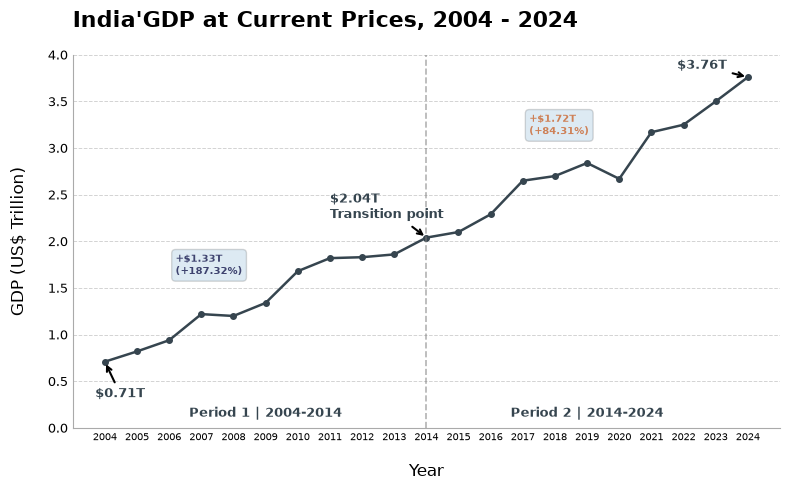

In [7]:
# Developing the Figure and Axes, we need two line charts.
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    df['Year'],
    df['GDP_Current(US$ Trillion)'],
    color='#36454F',
    linewidth=1.8,
    marker='o',
    markersize=4
)

# Format Axes and Labels
ax.set_title('India\'GDP at Current Prices, 2004 - 2024', fontsize=16, fontweight='bold', pad=20, loc='left')
ax.set_xlabel('Year', fontsize=12, fontweight='medium', labelpad=15)
ax.set_ylabel('GDP (US$ Trillion)', fontsize=12, fontweight='medium', labelpad=15)

ax.set_ylim(0, 4)
# Clean up the ticks
ax.tick_params(axis='x', which='major', labelsize=7, length=0)
ax.tick_params(axis='y', which='major', labelsize=9, length=0)
ax.set_xticks(df['Year'])

# add a subtle horizontal grid.
# zorder=0 pushes the grid behind the lines
ax.grid(axis='y', color='#d3d3d3', linestyle='--', linewidth=0.7, zorder=0)

# Strip away the top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['bottom'].set_color('#aaaaaa')


# Annotations
ax.annotate(
    '$0.71T',
    xy=(2004, 0.71),
    xytext=(2003.7, 0.33),
    arrowprops=dict(arrowstyle='->', lw=1.5),
    fontsize=9,
    fontweight='bold',
    color='#36454F'
)

ax.annotate(
    '$2.04T\nTransition point',
    xy=(2014, 2.04),
    xytext=(2011, 2.25),
    arrowprops=dict(arrowstyle='->', lw=1.5),
    fontsize=9,
    fontweight='bold',
    color='#36454F'
)

ax.annotate(
    '$3.76T',
    xy=(2024, 3.76),
    xytext=(2021.8, 3.85),
    color='#36454F',
    arrowprops=dict(arrowstyle='->', lw=1.5),
    fontsize=9,
    fontweight='bold'
)

# Vertical lines separating the two periods
ax.axvline(
    x=2014,
    linestyle='--',
    linewidth=1.2,
    color='gray',
    alpha=0.6
)

# Period 1 annotation
ax.annotate(
    "+$1.33T\n(+187.32%)",
    xy=(2009, 1.35),
    xytext=(2006.2, 1.65),
    color='#3E436F',
    fontsize=7,
    fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.4', alpha=0.15)
)

# Period 2 annotation
ax.annotate(
    "+$1.72T\n(+84.31%)",
    xy=(2019, 2.85),
    xytext=(2017.2, 3.15),
    color='#CE8056',
    fontsize=7,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.4", alpha=0.15)
)

# Period labels
ax.text(
    2009, 0.12,
    'Period 1 | 2004-2014',
    ha='center',
    fontsize=9,
    fontweight='bold',
    color='#36454F'
)

ax.text(
    2019, 0.12,
    'Period 2 | 2014-2024',
    ha='center',
    fontsize=9,
    fontweight='bold',
    color='#36454F',
)
# Adjust layout to prevent label cutoff and display
plt.tight_layout()
plt.show()

#### 2. **How fast did India's real GDP grow?**
- Annual real GDP gowth rate
- Average growth rate during each period
- Compound growth of real GDP

Let's first find out the Average and CAGR of Real GDP...

#### **Average growth rate during each period**

In [8]:
period_1_df = df[(df['Year'] > 2004) & (df['Year'] <=2014)]
period_2_df = df[(df['Year'] >= 2015) & (df['Year'] <=2024)]

# let's calculate average growth rate during each period.
avg_period_1 = round(float(period_1_df['GDP_Growth(annual%)'].mean()), 2)

avg_period_2 = round(float(period_2_df['GDP_Growth(annual%)'].mean()), 2)

print(f'Average growth rate for period 1: {avg_period_1}%')
print(f'Average growth rate for period 2: {avg_period_2}%')

Average growth rate for period 1: 6.76%
Average growth rate for period 2: 5.92%


#### **Compound Anual Growth rate (CAGR) of Real GDP**

**Formula**

> **(Ending Value / Beginning Value) ^1/n - 1**

where n = Number of years between the beginning end ending values.

- **Period 1:** Ending value = GDP (Constant) of year 2014 and Beginning vlaue = GDP (Constant) of year 2004.
- **Period 2:** Ending value = GDP (Constant) of year 2024 and Beginning value = GDP (Constant) of year 2014.

Both period contains 10 years between the beginning and ending values, hence _n_ = 10

**NOTE:** The Database contains Real GDP having the base year 2015

In [9]:
# let's findout the Constant(Real) GDP values at each stage for both periods.
gdp_constant_2004: float = df.loc[df['Year']==2004, 'GDP_Constant(2015 US$ Trillion)'].item()
gdp_constant_2014: float = df.loc[df['Year']==2014, 'GDP_Constant(2015 US$ Trillion)'].item()
gdp_constant_2024: float = df.loc[df['Year']==2024, 'GDP_Constant(2015 US$ Trillion)'].item()

# CAGR of Real GDP for each period
cagr_period_1 = ((gdp_constant_2014 / gdp_constant_2004) ** (1/10) - 1) * 100
cagr_period_2 = ((gdp_constant_2024 / gdp_constant_2014) ** (1/10) - 1) * 100

print(f'CAGR of Real GDP for Period 1 (2004-2014): {round(cagr_period_1, 2)}%')
print(f'CAGR of Real GDP for Period 2 (2014-2024): {round(cagr_period_2, 2)}%')


CAGR of Real GDP for Period 1 (2004-2014): 6.8%
CAGR of Real GDP for Period 2 (2014-2024): 5.81%


> "India's real GDP grew at a compound annual rate of 6.8% during 2004-2014, compared with 5.81% during 2014-2024, This indicates that the earlier/later period experienced the faster long-term compounded pace of real economic expansion."

> "2004-2014 had the faster real GDP growth trajectory overall than 2014-2024, athought the second period contained the dramatic 2020 contraction and 2021 rebound.

#### **Annotated line plot to compare the Growth trajectory of Periods**

**2004 - 2014**

- Average Growth rate in Real GDP = 6.76%
- CAGR in Real GDP = 6.8%

**2014 - 2024**

- Average Growth rate in Real GDP = 5.92%
- CAGR in Real GDP = 5.81%

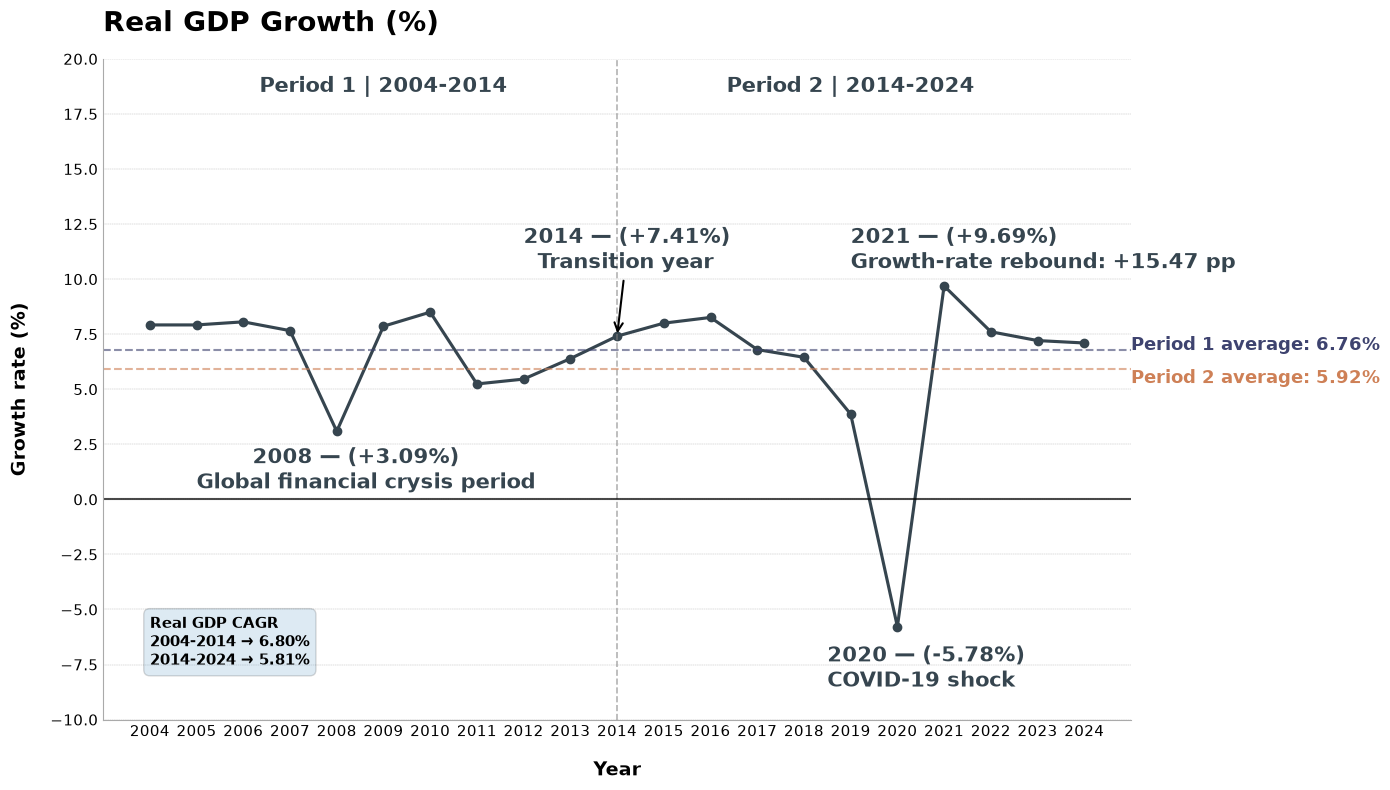

In [10]:
# Create the Figure and Axes
fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(
    df['Year'],
    df['GDP_Growth(annual%)'],
    color='#36454F',
    linewidth=2.25,
    marker='o',
    markersize=6
)

ax.set_title('Real GDP Growth (%)', fontsize=20, fontweight='bold', pad=20, loc='left')
ax.set_xlabel('Year', fontsize=14, fontweight='bold', labelpad=15)
ax.set_ylabel('Growth rate (%)', fontsize=14, fontweight='bold', labelpad=15)

# Clean up the ticks
ax.tick_params(axis='x', which='major', labelsize=11, length=0)
ax.tick_params(axis='y', which='major', labelsize=11, length=0)
ax.set_xticks(df['Year'])

# setting the Y-axis limit.
ax.set_ylim(-10, 14)
ax.set_yticks([-10.0, -7.5, -5.0, -2.5, 0, 2.5, 5.0, 7.5, 10.0, 12.5, 15.0, 17.5, 20.0 ])

# Removing the spines of top and right side for professional touch.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['bottom'].set_color('#aaaaaa')

# Adding a subtle grid, "zorder" will push the grid line under the line plot.
ax.grid(axis='y', linestyle='--', linewidth=0.3, zorder=0)

ax.annotate(
    f'{' '*8}2008 — (+3.09%)\nGlobal financial crysis period',
    xy=(2008, 3.09),
    xytext=(2005, 0.5),
    color='#36454F',
    fontsize=15,
    fontweight='bold'
)

ax.annotate(
    '2014 — (+7.41%)\n  Transition year',
    xy=(2014, 7.41),
    xytext=(2012, 10.5),
    arrowprops=dict(arrowstyle='->', lw=1.5),
    fontsize=15,
    fontweight='bold',
    color='#36454F'
)

ax.annotate(
    '2020 — (-5.78%)\nCOVID-19 shock',
    xy=(2020, -5.78),
    xytext=(2018.5, -8.5),
    fontsize=15,
    fontweight='bold',
    color='#36454F'
)

ax.annotate(
    '2021 — (+9.69%)\nGrowth-rate rebound: +15.47 pp',
    xy=(2021, 9.69),
    xytext=(2019, 10.5),
    fontsize=15,
    fontweight='bold',
    color='#36454F'
)

# vertical line separating the two period.
ax.axvline(
    x=2014,
    linestyle='--',
    linewidth=1.2,
    color='gray',
    alpha=0.6
)

# Horizontal line for averages.
ax.axhline(
    y=6.76,
    linestyle='--',
    linewidth=1.5,
    color='#3E436F',
    alpha=0.6
)

ax.axhline(
    y=5.92,
    linestyle='--',
    linewidth=1.5,
    color='#CE8056',
    alpha=0.6
)

ax.text(
    2025,
    7.0,
    f'Period 1 average: 6.76%',
    color='#3E436F',
    fontsize=13,
    fontweight='bold',
    va='center'
)

ax.text(
    2025,
    5.5,
    f'Period 2 average: 5.92%',
    color='#CE8056',
    fontsize=13,
    fontweight='bold',
    va='center'
)

# The 0 percent line.
ax.axhline(
    y=0,
    color='black',
    linewidth=1.5,
    alpha=0.7
)
# Annotation for period 1
ax.annotate(
    'Real GDP CAGR\n2004-2014 → 6.80%\n2014-2024 → 5.81%',
    xy=(2004, -7.5),
    xytext=(2004, -7.5),
    fontsize=11,
    fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.4", alpha=0.15)
)

# Period labels
ax.text(
    2009, 18.5,
    'Period 1 | 2004-2014',
    ha='center',
    fontsize=15,
    fontweight='bold',
    color='#36454F'
)

ax.text(
    2019, 18.5,
    'Period 2 | 2014-2024',
    ha='center',
    fontsize=15,
    fontweight='bold',
    color='#36454F',
)


plt.tight_layout()
plt.show()

#### 3. **How did GDP per capita change?**
- GDP per capita at the beginning and end
- Percentage change
- Real GDP per capita, where appropriate
- Compare GDP growth with population growth

This is crucial because this might answers: **Total GDP can grow rapidly while GDP per person grows much more slowly.**

#### **Data Ingestion**

In [11]:
# File Path
file_path: str = 'Cleaned_datasets/Production/production_dataset_ver02.parquet'

if not os.path.exists(file_path):
    raise FileNotFoundError(f'[CRITICAL] {file_path} does not exist!')

try:
    df_ver02 = pd.read_parquet(file_path)
    print(f'[SUCESS] File loaded!\nContaining {len(df_ver02)} number of rows')
except Exception as e:
    print(f'[CRITICAL] Could not Read the file: {file_path}')

[SUCESS] File loaded!
Containing 21 number of rows


In [41]:
df_ver02

,Year,Inflation(annual %),GDP_Current(US$ Trillion),GDP_Constant(2015 US$ Trillion),GDP_Growth(annual%),GDP_PPP(Current US$ Trillion),GDP_Per_Capita(Current US$),GDP_PC_(Constant 2015 US$),Population_growth_(annual %),Total_Population(billion)
0,2004,5.73,0.71,1.01,7.92,2.96,624.26,892.60,1.70,1.14
1,2005,5.62,0.82,1.09,7.92,3.29,710.49,947.73,1.63,1.15
2,2006,8.40,0.94,1.18,8.06,3.67,801.67,1008.23,1.56,1.17
3,2007,6.94,1.22,1.27,7.66,4.06,1021.89,1069.25,1.51,1.19
4,2008,9.19,1.20,1.31,3.09,4.26,992.52,1086.51,1.44,1.21
5,2009,7.04,1.34,1.42,7.86,4.63,1094.95,1155.10,1.45,1.23
6,2010,10.53,1.68,1.54,8.50,5.08,1347.52,1235.16,1.45,1.24
7,2011,8.73,1.82,1.62,5.24,5.46,1445.46,1281.61,1.42,1.26
8,2012,7.93,1.83,1.70,5.46,5.99,1429.32,1333.10,1.37,1.28
9,2013,6.19,1.86,1.81,6.39,6.31,1432.84,1399.45,1.33,1.30


#### **GDP per capita (Current US$) at the beginning and end of each period**
| | **Beginning** | **Ending** |
|-|---------------|------------|
|**Period 1** | 2004 | 2014 |
|**Period 2** | 2014 | 2024 | 

In [13]:
# let's find out then
# GDP per capita at the beginning of Period one.
curr_per_capita_2004: float = df_ver02.loc[df_ver02['Year']==2004, 'GDP_Per_Capita(Current US$)'].item()

# GDP per capita Transition period (ending for period 1 and beginning for period 2)
curr_per_capita_2014: float = df_ver02.loc[df_ver02['Year']==2014, 'GDP_Per_Capita(Current US$)'].item()

# GDP per capita at the end of Period two.
curr_per_capita_2024: float = df_ver02.loc[df_ver02['Year']==2024, 'GDP_Per_Capita(Current US$)'].item()


print(f'Period 1 Current GDPPC (2015 US$): Beginning -> {curr_per_capita_2004} AND Ending -> {curr_per_capita_2014}')
print(f'Period 2 Current GDPPC (2015 US$): Beginning -> {curr_per_capita_2014} AND Ending -> {curr_per_capita_2024}')

Period 1 Current GDPPC (2015 US$): Beginning -> 624.26 AND Ending -> 1553.88
Period 2 Current GDPPC (2015 US$): Beginning -> 1553.88 AND Ending -> 2591.99


#### **Total percentage Change in GDP Per Capita (Current US$)**

**Formula**

> **((Ending Per Capita - Beginning Per Capita) * 100 )/ Beginning Per Capita**

In [14]:
period_1_per_change = ((curr_per_capita_2014 - curr_per_capita_2004)*100) / curr_per_capita_2004
period_2_per_change = ((curr_per_capita_2024 - curr_per_capita_2014)*100) / curr_per_capita_2014

print(f'Total Percentage change in Current GDP Per Capita for Period 1: {round(period_1_per_change, 2)}%')
print(f'Total Percentage change in Current GDP Per Capita for Period 2: {round(period_2_per_change,2)}%')

Total Percentage change in Current GDP Per Capita for Period 1: 148.92%
Total Percentage change in Current GDP Per Capita for Period 2: 66.81%


#### **GDP per capita (Constant 2015 US$) at the beginning and end of each period**

In [15]:
# let's find out then

# GDP per capita at the beginning of Period one.
per_capita_2004: float = df_ver02.loc[df_ver02['Year']==2004, 'GDP_PC_(Constant 2015 US$)'].item()

# GDP per capita Transition period (ending for period 1 and beginning for period 2)
per_capita_2014: float = df_ver02.loc[df_ver02['Year']==2014, 'GDP_PC_(Constant 2015 US$)'].item()

# GDP per capita at the end of Period two.
per_capita_2024: float = df_ver02.loc[df_ver02['Year']==2024, 'GDP_PC_(Constant 2015 US$)'].item()


print(f'Period 1 Real GDPPC (Current US$): Beginning -> {per_capita_2004} AND Ending -> {per_capita_2014}')
print(f'Period 2 Real GDPPC (Current US$): Beginning -> {per_capita_2014} AND Ending -> {per_capita_2024}')

Period 1 Real GDPPC (Current US$): Beginning -> 892.6 AND Ending -> 1484.32
Period 2 Real GDPPC (Current US$): Beginning -> 1484.32 AND Ending -> 2366.83


#### **Total percentage Change in GDP Per Capita (Constant US$)**

**Formula**

> **((Ending Per Capita - Beginning Per Capita) * 100 )/ Beginning Per Capita**

In [16]:
period_1_per_change = ((per_capita_2014 - per_capita_2004)*100) / per_capita_2004
period_2_per_change = ((per_capita_2024 - per_capita_2014)*100) / per_capita_2014

print(f'Total Percentage change in Real GDP Per Capita for Period 1: {round(period_1_per_change, 2)}%')
print(f'Total Percentage change in Real GDP Per Capita for Period 2: {round(period_2_per_change,2)}%')

Total Percentage change in Real GDP Per Capita for Period 1: 66.29%
Total Percentage change in Real GDP Per Capita for Period 2: 59.46%


#### **CAGR for Real GDP per capita**

**Formula**

> **CAGR Real GDPPC = (Real GDPPC end/Real GDPPC begin) ** 1/n - 1**<br> Where _n_ is Total number of year between each period.

In [17]:
# CAGR for Real GDPPC for Period 1.
cagr_real_gdppc_per_1: float = ((per_capita_2014 / per_capita_2004) ** (1/10)-1) * 100
cagr_real_gdppc_per_2: float = ((per_capita_2024 / per_capita_2014) ** (1/10)-1) * 100

print(f"CAGR For Period 1 (Real GDPPPC): {round(cagr_real_gdppc_per_1, 2)}%")
print(f"CAGR For Period 2 (Real GDPPPC): {round(cagr_real_gdppc_per_2, 2)}%")

CAGR For Period 1 (Real GDPPPC): 5.22%
CAGR For Period 2 (Real GDPPPC): 4.78%


#### **Comparing GDP growth with population growth**

#### **Population data section**

we'll find out for each period:
- Total Population change in number.
- Total Population change in percentage.
- average percentage of Population change.
- CAGR of Population.


Let's start then

In [18]:
# Total Population for "Period 1" change in number. (Population in 2014 - 2004)
pop_2004: float = df_ver02.loc[df['Year']==2004, 'Total_Population(billion)'].item()
pop_2014: float = df_ver02.loc[df['Year']==2014, 'Total_Population(billion)'].item()
pop_2024: float = df_ver02.loc[df['Year']==2024, 'Total_Population(billion)'].item()

pop_inc_period_1 = round((pop_2014 - pop_2004), 2)

# similarly
pop_inc_period_2 = round((pop_2024 - pop_2014), 2)

print(f'Total Population increase (billion):\nPeriod 1 -> {pop_inc_period_1}\nPeriod 2 -> {pop_inc_period_2}')

Total Population increase (billion):
Period 1 -> 0.17
Period 2 -> 0.14


In [19]:
# Total percentage change in Population
delta_per_pop_period_1 = ((pop_2014 - pop_2004) / pop_2004 ) * 100
delta_per_pop_period_2 = ((pop_2024 - pop_2014) / pop_2014 ) * 100

print(f'Percentage change in Population:\nPeriod 1 -> {round(delta_per_pop_period_1, 2)}%\nPeriod 2 -> {round(delta_per_pop_period_2, 2)}%')

Percentage change in Population:
Period 1 -> 14.91%
Period 2 -> 10.69%


In [20]:
# Average Annual population growth rate.

# exclusion of 2004 was necessary since it contains the data of 2003 -2004.
period_1_data = df_ver02[(df_ver02['Year'] > 2004) & (df_ver02['Year']<=2014)]
period_2_data = df_ver02[(df_ver02['Year'] > 2014) & (df_ver02['Year']<=2024)]

avg_pop_per_period_1 = period_1_data['Population_growth_(annual %)'].mean().round(2)
avg_pop_per_period_2 = period_2_data['Population_growth_(annual %)'].mean().round(2)

print(
    f'Average annual population growth rate:\nPeriod 1 -> {avg_pop_per_period_1}%\nPeriod 2 -> {avg_pop_per_period_2}%'
)

Average annual population growth rate:
Period 1 -> 1.44%
Period 2 -> 1.0%


In [21]:
# CAGR of Population change:
cagr_pop_period_1: float = ((pop_2014/pop_2004)**(1/10) - 1) * 100

cagr_pop_period_2: float = ((pop_2024/pop_2014)**(1/10) - 1) * 100

print(
    f'CAGR for Population:\nPeriod 1 -> {round(cagr_pop_period_1,2)}%\nPeriod 2 -> {round(cagr_pop_period_2,2)}%'
)

CAGR for Population:
Period 1 -> 1.4%
Period 2 -> 1.02%


#### **What have we established for question 3?**

> **India's real GDP per capita increased well during both periods, but at a slower rate in terms of total Real GDP because the population continued to grow. Real GDP per capita grew at a CAGR of 5.22% during 2004-2014 and 4.78% during 2014-2024. Population growth was also slower in the second period, declining from a CAGR of 1.40% to 1.02%. Thus, the first period experienced faster growth in both total real output and real output per person, while the second period benefited from slower population growth, which helped limit the reduction in per-capiata growth.**

#### **Visualization: "growth decompositio" grouped bar chart**

| **Growth measure** | **2004-2014** | **2014-2024** |
|--------------------|---------------|---------------|
| **Real GDP CAGR** | 6.80% | 5.81% |
| **Population CAGR** | 1.40% | 1.02% |
| **Real GDP per capita CAGR | 5.22% | 4.78% |

we have two groups:
- 2004-2014
- 2014-2024

And three metrics inside each group:
- Real GDP CAGR
- Population CAGR
- Real GDP per capita CAGR


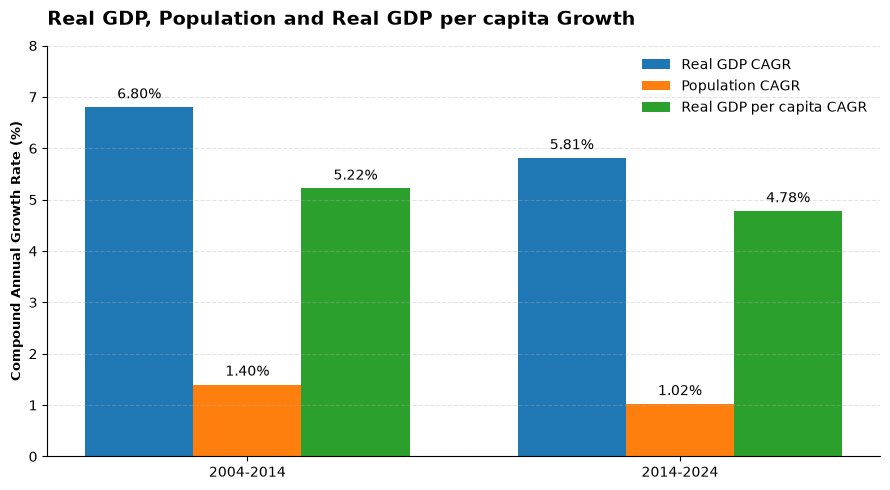

In [22]:
import numpy as np
# Data
periods = ['2004-2014', '2014-2024']

real_gdp_cagr = [cagr_period_1, cagr_period_2] # Real GDP CAGR
real_gdppc_cagr = [cagr_real_gdppc_per_1, cagr_real_gdppc_per_2] 
population_cagr = [cagr_pop_period_1, cagr_pop_period_2]

# BAR position
x = np.arange(len(periods))

width = 0.25

# Creating figure
fig, ax = plt.subplots(figsize=(9, 5))

# Creating grouped bars
bars_gdp = ax.bar(
    x-width,
    real_gdp_cagr,
    width,
    label='Real GDP CAGR'
)

bars_pop = ax.bar(
    x,
    population_cagr,
    width,
    label='Population CAGR'
)

bars_gdppc = ax.bar(
    x + width,
    real_gdppc_cagr,
    width,
    label='Real GDP per capita CAGR'
)

# Adding value labels above each bar
ax.bar_label(
    bars_gdp,
    fmt='%.2f%%',
    padding=4
)

ax.bar_label(
    bars_pop,
    fmt='%.2f%%',
    padding=4
)

ax.bar_label(
    bars_gdppc,
    fmt='%.2f%%',
    padding=4
)

# Titles and Labels
ax.set_title(
    "Real GDP, Population and Real GDP per capita Growth",
    fontsize=14,
    fontweight='bold',
    loc='left',
    pad=15
)

ax.set_ylabel(
    'Compound Annual Growth Rate (%)',
    fontsize=9,
    fontweight='bold'
)

# X-Axis
ax.set_xticks(x)
ax.set_xticklabels(periods)

# Grid
ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.35
)

ax.grid(
    axis='x',
    visible=False
)

# Lengend

ax.legend(
    frameon=False,
    loc='upper right'
)

# Clean up spines.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Extra space for labels
ax.set_ylim(0, 8)

# final Layout
plt.tight_layout()

plt.show()

#### **The analytical conclusion**

> **Real GDP grew faster than population in both periods, resulting in subtantial growth in real GDP per capita. However, both total real GDP growth and real GDP per capita growth were slower during 2014-2024 than during 2004-2014. At the same time, population growth also slowed, from 1.40% to 1.02% per year.**

### 4. **Was economic growth consistent or vaolatile?** For each period:
   - Annual GDP growth rate
   - Mean/average growth
   - Standard deviation of growth
   - Maximum growth rate
   - Minimum growth rate
   - Number of years with particularly weak growths

Then ask: **Was one period characterized by more stable growth, while the other experienced larger fluctuations?**

This it the point where our analysis moves from **"How fast did India grow?"** to **"How stable was that growth?"**

> **High growth and stable growth are not the same thing.**

#### **1. Annual GDP growth rate**

our line chart from **Question 2** is useful here.

**The raw yearly series**

It answers:
> **What happened in each individual year?**

our chart includes:
- **2008** -> 3.09%
- **2020** -> -5.78%
- **2021** -> 9.69%

This series is the foundation of the entire volatility analysis.

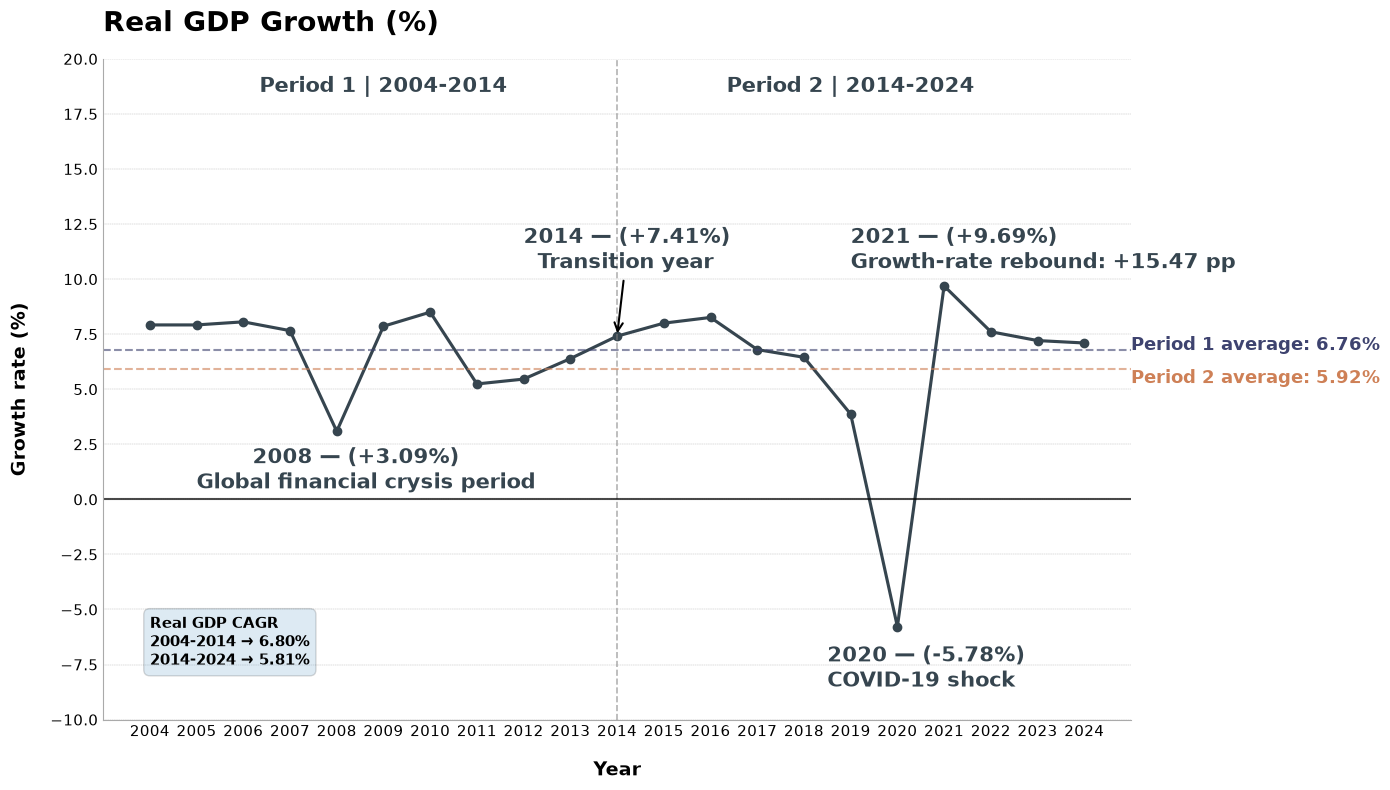

#### **2. Mean / average growth**

we've already calulated, as we can see the two lines between the chart, shows:
- Period 1 average: **6.76%**
- Period 2 average: **5.92%**

Let's perform further analytics...

#### **2. Standard deviation of growth — the main volatile**

This is really important. Since, it tell's how far does the growth shifted from the **period's average**?

In simple terms:

**Low standard deviation** -> growth rates stayed relatively close to the average -> **more consistent**

**High standard deviation** -> growth rates fluctuted more -> **more volatile** 

In [23]:
# let's find out, STANDARD DEVIATION.

# Period 1: 2005 - 2014 (2004 will be excluded because it contains annual
# growth of 2003 - 2004)
df_period1 = (df_ver02['Year']>2004) & (df_ver02['Year']<=2014)
period1_gdp_growth_std = df_ver02.loc[df_period1, 'GDP_Growth(annual%)'].std(ddof=0).round(2)

# Period 2: 2015-2024
df_period2 = (df['Year']>=2015) & (df_ver02['Year']<=2024)
period2_gdp_growth_std = df_ver02.loc[df_period2, 'GDP_Growth(annual%)'].std(ddof=0).round(2)

print(
    f'Standard deviation of GDP growth:\nPeriod 1 -> {period1_gdp_growth_std}\nPeriod 2 -> {period2_gdp_growth_std}'
)

Standard deviation of GDP growth:
Period 1 -> 1.62
Period 2 -> 4.15


#### **Why use `ddof=0` while calculating Standard Deviation**

**The term:**

_DDOF_ stands for **Delta Degrees of Feedom**, When calculating standard deviation, we take all the squared differences from the mean and divide them by a specific number to find the average variance. The divisor is: _N_ - ddof
(where _N_ is our total number of data points).

**Degrees of Freedom** referst to the number of independent values in a calculation that are free to vary. **Delta** means the "change" or "difference"—specifically, exactly how much you are substracting from _N_.

Here is how that translates to 0 and 1:

**`ddof=0` (Population Standard Deviation)**
- _The math_: we divide by _N_ - 0, which is just _N_.

- _The meaning_: we use this when we have the **entire population** of data.

- _Why 0?_: Because we have 100% of the information, we aren't trying to estimate anything outside of the dataset. No data points are constrained by estimations, so we substract nothing. We lose 0 degrees of freedom.

**`ddof=1` (Sample Standard Deviation)**
- _The math_: we divide _N_ - 1.

- _The Meaning_: We use this when our data is only a **sample**(a subset), but we want to estimate the standard deviation of the massive population it came from.

- _Why 1?_: To estimate the population's spread from a small sample, we first have to calculate the smaple's mean. The moment we calculate that mean, our data points are no longer entirely independent. If we know the mean and all but one of the data points, we can use basic algebra to figure out the exact value of the final missing point. Because that final point is locked  into place by the math, it is no longer "free to vary". Therefore, we have lost exactly **1 degree of freedom**.

Substracting 1 from the denominator makes the resulting standard deviation slightly larger. This is known as _Bessels's_ correction, and it prevents us from accidentlly underestimating the true population's variance when working with limited sample.

**The Pandas vs. NumPY Trap**

- **Pandas** assumes our data is a sample, so `.std()` defaults to `ddof=1`.
- **NumPy** assumes our data is whole population, so `np.std()` defaults to `ddof=0`.

#### **4. Maximum growth rate**

This answers:
> **What was the strongest single year of real GDP growth?**

In [24]:
# maximum GDP growth year from Period 1
max_growth_period1 = period_1_df['GDP_Growth(annual%)'].max()

# maximum GDP growth year from Period 2
max_growth_period2 = period_2_df['GDP_Growth(annual%)'].max()

print(
    f'Maximum GDP Growth (annual%):\nPeriod 1 -> {max_growth_period1}%\nPeriod 2 -> {max_growth_period2}%'
)

Maximum GDP Growth (annual%):
Period 1 -> 8.5%
Period 2 -> 9.69%


#### **5. Minimum Growth Rate**

This answers:
> **What was the weakest single year?**

In [25]:
# Minimum GDP growth year from period 1
min_growth_period1 = period_1_df['GDP_Growth(annual%)'].min()

# Minimum GDP growth year from period 2
min_growth_period2 = period_2_df['GDP_Growth(annual%)'].min()

print(
    f'Minimum GDP Growth (annual%)\nPeriod 1 -> {min_growth_period1}%\nPeriod 2 -> {min_growth_period2}%'
)

Minimum GDP Growth (annual%)
Period 1 -> 3.09%
Period 2 -> -5.78%


#### **6. "Number of years with particularly weak growth"-this needs a rule**

What exactly conts as **"weak"**?

we need to establish a threshold **before counting**, otherwise we can accidentally choose a threshold that gives us the conclusion **WE** want.

One of the transparent threshold could be:

> **Weak growth = annual real GDP growth below 4%** and we add another metrics<br>**Contraction = annual real GDP growth below 0%**



In [26]:
# let's count then
weak_years_p1 = period_1_df[period_1_df['GDP_Growth(annual%)'] < 4.0]
weak_years_p2 = period_2_df[period_2_df['GDP_Growth(annual%)'] < 4.0]

# contraction year
contraction_years_p1 = period_1_df[period_1_df['GDP_Growth(annual%)'] < 0.0]
contraction_years_p2 = period_2_df[period_2_df['GDP_Growth(annual%)'] < 0.0]

print(
    f'Weak growth years:\nPeriod 1 = {len(weak_years_p1)}\nPeriod 2 = {len(weak_years_p2)}'
)

print(
    f'Contraction years:\nPeriod 1 = {len(contraction_years_p1)}\nPeriod 2 = {len(contraction_years_p2)}'
)

Weak growth years:
Period 1 = 1
Period 2 = 2
Contraction years:
Period 1 = 0
Period 2 = 1


#### **Final Result for Question 4**
| **Metric** | **2005-2014** | **2014-2024** |
|------------|---------------|---------------|
| Average Growth (Real GDP) | 6.76% | 5.92% |
| Standard Deviation | 1.62 | 4.15 |
| Maximum | 8.5% (2010) | 9.69% (2021) |
| Minimum | 3.09% (2008) | -5.78% (2020) |
| Weak years (<4%) | 1 | 2 |
| Contraction years (<0%) | 0 | 1 |

#### **Visualization**

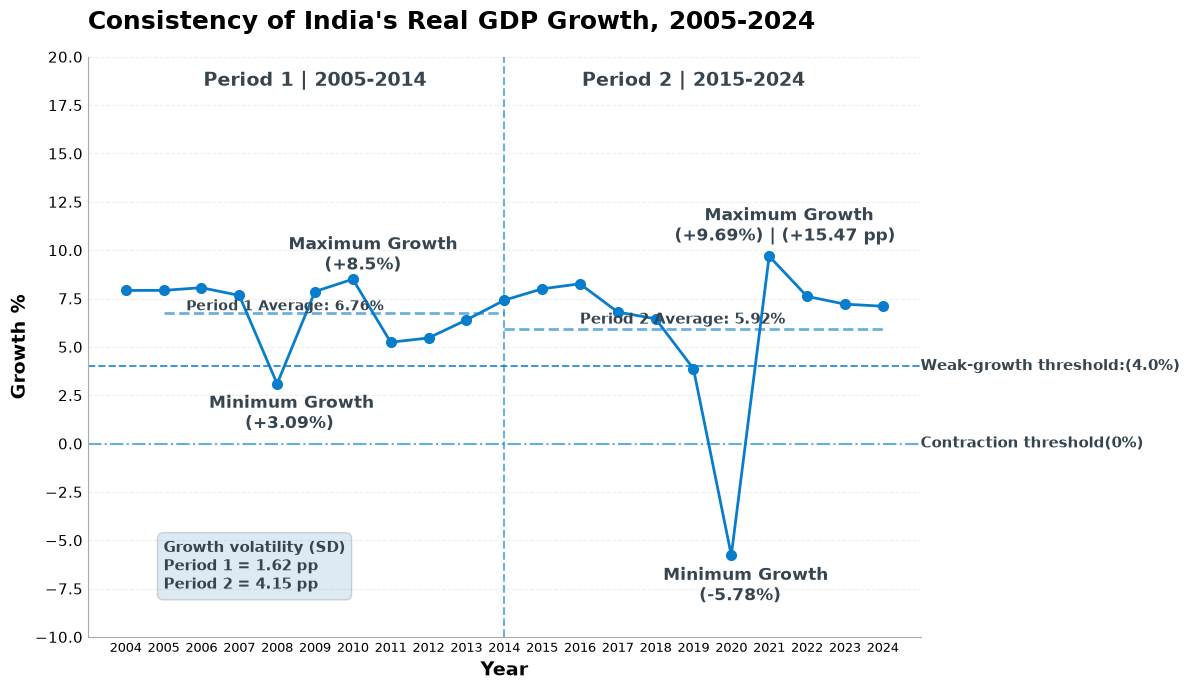

In [39]:
# Creating the figure and axes.
fig, ax = plt.subplots(figsize=(12, 7))

# plotting.
ax.plot(
    df_ver02['Year'],
    df_ver02['GDP_Growth(annual%)'],
    linewidth=2,
    marker='o',
    markersize=7,
    color="#087DCB"
)

# Titles and Labels.
ax.set_title('Consistency of India\'s Real GDP Growth, 2005-2024', fontsize=18, fontweight='bold', loc='left', pad=20)
ax.set_xlabel('Year', fontsize='14', fontweight='bold')
ax.set_ylabel('Growth %', fontsize='14', fontweight='bold')

# Setting the y-axis values limit.
ax.set_ylim(-10, 20)

# Setting x-axis ticks and y-axis ticks
ax.tick_params(axis='x', which='major', labelsize=9.5, length=0)
ax.tick_params(axis='y', which='major', labelsize=11, length=0)
ax.set_xticks(df_ver02['Year'])
y_ticks = [-10, -7.5, -5.0, -2.5, 0, 2.5, 5.0, 7.5, 10, 12.5, 15.0, 17.5, 20.0]
ax.set_yticks(y_ticks)

# Cleaning the spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['bottom'].set_color('#aaaaaa')

# Annotations For period 1
ax.annotate(
    f'Maximum Growth\n{' '*6}(+8.5%)',
    xy=(2010, 8.5),
    xytext=(2008.3, 9.0),
    fontsize=12,
    fontweight='bold',
    color='#36454F'
)

ax.annotate(
    f'Minimum Growth\n{' '*6}(+3.09%)',
    xy=(2008, 3.09),
    xytext=(2006.2, 0.8),
    fontsize=12,
    fontweight='bold',
    color='#36454F'
)

# Annotation for Period 2
ax.annotate(
    f'{' '*5}Maximum Growth\n(+9.69%) | (+15.47 pp)',
    xy=(2021, 9.69),
    xytext=(2018.5, 10.5),
    fontsize=12,
    fontweight='bold',
    color='#36454F'
)

ax.annotate(
    f'Minimum Growth\n{' '*6}(-5.78%)',
    xy=(2020, -5.78),
    xytext=(2018.2, -8.1),
    fontsize=12,
    fontweight='bold',
    color='#36454F'
)

# Grid
ax.grid(axis='y', alpha=0.2, linestyle='--', zorder=0)

# lines.
ax.axvline(
    x=2014,
    linestyle='--',
    color='#087DCB',
    linewidth=1.5,
    alpha=0.6
    )

ax.axhline(
    y=0,
    linestyle='-.',
    linewidth='1.5',
    alpha=0.6,
    color='#087DCB'
)

# Horizontal line for averages.

ax.hlines(
    6.76,
    2005,
    2014,
    linestyles='--',
    linewidth=2.0,
    color='#087DCB',
    alpha=0.6
)

ax.hlines(
    y=5.92,
    xmin=2014,
    xmax=2024,
    linestyles='--',
    linewidth=2.0,
    color='#087DCB',
    alpha=0.6
)

# Horizontal line for weak years.
ax.axhline(
    y=4.0,
    linestyle='--',
    linewidth=1.4,
    alpha=0.8,
    color='#087DCB'
)

# Texts
ax.text(
    2005.6, 6.89,
    'Period 1 Average: 6.76%',
    fontsize=10,
    fontweight='bold',
    color='#36454F'
)
ax.text(
    2016, 6.2,
    'Period 2 Average: 5.92%',
    fontsize=11,
    fontweight='bold',
    color='#36454F'
)
ax.text(
    2025, 3.8,
    'Weak-growth threshold:(4.0%)',
    fontsize=11,
    fontweight='bold',
    color='#36454F'
)
ax.text(
    2025, -0.2,
    'Contraction threshold(0%)',
    fontsize=11,
    fontweight='bold',
    color='#36454F'
)

# Period text
ax.text(
    2009, 18.5,
    'Period 1 | 2005-2014',
    fontsize=14,
    fontweight='bold',
    color='#36454F',
    ha='center'

)
ax.text(
    2019, 18.5,
    'Period 2 | 2015-2024',
    fontsize=14,
    fontweight='bold',
    color='#36454F',
    ha='center'
)

ax.annotate(
    'Growth volatility (SD)\nPeriod 1 = 1.62 pp\nPeriod 2 = 4.15 pp',
    xy=(2005, -7.5),
    xytext=(2005, -7.5),
    fontsize=11,
    fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.4", alpha=0.15),
    color='#36454F'
)
plt.tight_layout()
plt.show()

#### **Coclusion**

>**India's Real GDP growth was considerably more stable during 2004-2014 than during 2014-2024. Average annual real GDP growth was higher in the first period (6.76% versus 5.92%), while the standard deviation of annual growth was much lower (1.62 versus 4.15 percentage points). The first period recorded no contraction years and only one year below the 4% weak-growth threshold. In contrast, the second period experienced two weak-growth threshold. In contrast, the second period experienced two weak-growth years and one contraction year, with growth falling to -5.78% in 2020 before rebounding sharply to 9.69% in 2021. which also indicates that 2014-2024 was the more volatile period.** 

>**India's real GDP contracted by 5.78% in 2020 and rebounded by 9.69% in 2021. Across the two years, real GDP increased by approximately 3.35% relative to its 2019 level, indicating that the 2021 rebound more than recovered the 2020 contraction.**

### **Q5. What did the growth trajectory actually look like?**

Instead of comparing only two endpoints, we'll plot the entire 2004-2024trajectory.

We'll look for:
- sustained acceleration
- slowdown
- unusually strong years
- unusually weak years
- major turning points
- periods of recovery

This matters because two periods can have the same average growth but completely different trajectories.

For that we have already build the tracjectory chart in question 2. And for this question we will gonna use the same chart. That shows **India's real GDP annual growth rate**.

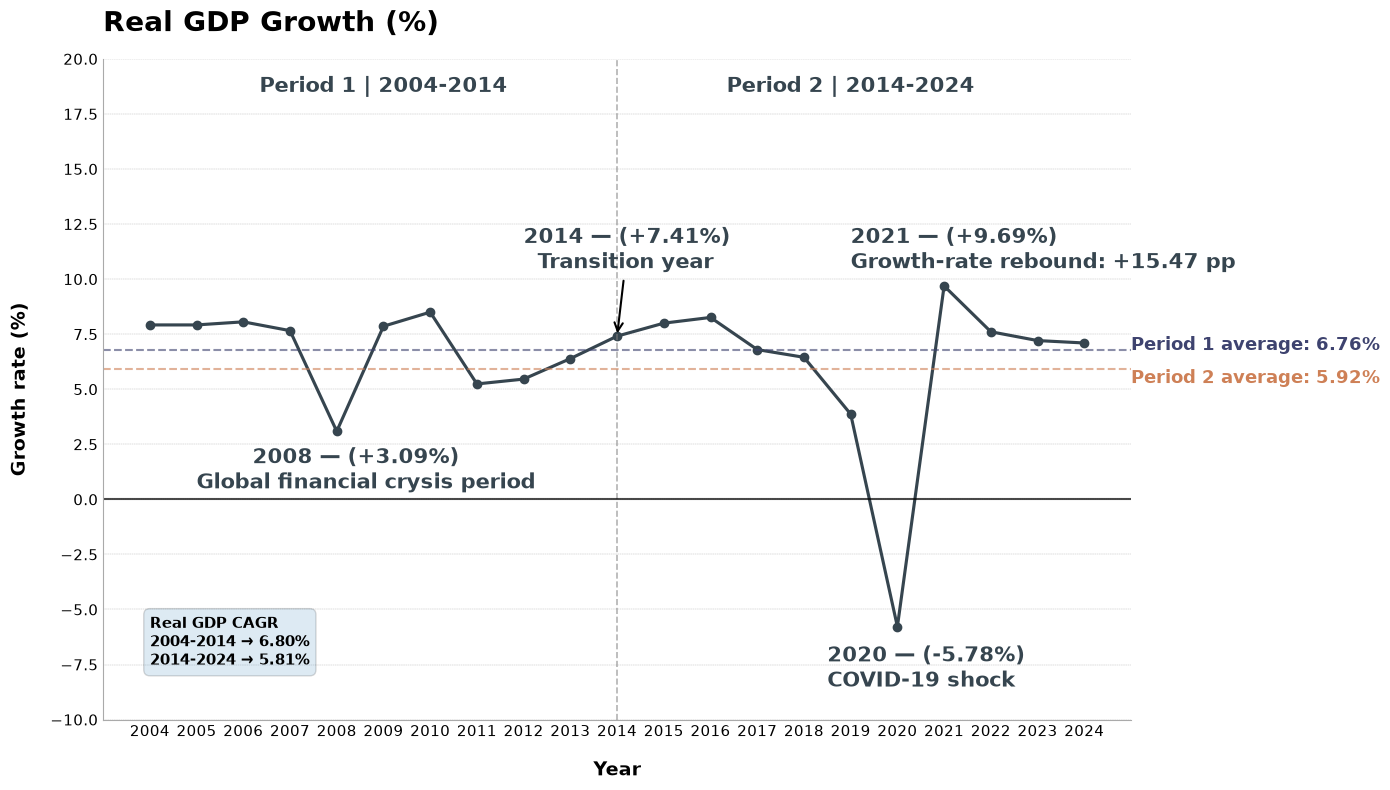

This is my interpretation, However I'll highly suggest to not give attention to this, I just keep it to prove my learning period. The real interpretation is just below this...
#### **Sustained acceleration**

Between the year 2012 to 2016 India's real GDP was in Sustained accelaration

#### **Slowdown**

We could see multiple slowdown years in the India's real GDP growth trajectory, those years are 2007(a minimal slowdown) leading to 2008 Global financial crysis impact, and just after the rebound during 2008-2010, a major slowdown happened in 2010-2011, then the **sustained accelartion periods came in till the year 2016, and from then the real GDP continously fall (slow to grow) towards the major contraction 2020 (Pendamic shock), and then again a major rebound in 2021, the slowdown started again till 2024.

#### **unsually strong year**

we have 2009 and 2021 but If I define the term unusually then it's 2021.

#### **unsually weak year**

We does have 2008 and 2020, but there's another 2011.

#### **Major turning points**

I Use the major turning points to define the year 2011, and the years after 2016 we can see that there's no global financial or pandemic crysis but still we face major slowdowns, For India's economy I define those as the major turning points.

#### **periods of recovery**
I can't find any pattern here..I'd prefer and leave this to you to make me understand

### **A polished version of my trajectory analysis**

**Growth Trajectory of India's Real GDP, 2004-2024**

```text
India's real GDP growth followed a fluctuating trajectory rather than a uniform pattern of expansion. The series show several episodes of acceleration and slowdown, followed by major contraction and a sharp rebound.

The first notable slowdown occurred in 2008, when real GDP growth fell to 3.09%. Growth then rebounded to 7.86% in 2009 and 8.50% in 2010. A subsequent slowdown in 2011 reduced growth to 5.24%, but growth mementum recovered steadily through 2016, when the annual rate reached 8.26%.

From 2016 to 2020, the trajectory decelerate progressively. Growth declined from 8.26% in 2016 to 6.80% in 2017, 6.45% in 2018, and 3.87% in 2019, before turning negative at -5.78% in 2020. This was the most severe contraction in the series.

The year 2021 marked a sharp rebound, with real GDP growth reaching 9.69%. However, this was followed by a moderation in the growth rate, which declined to 7.61% 2022, 7.21% in 2023, and 7.10% 2024. Despite this deceleration, growth remained positive throuhgout 2022-2024.

Overall, the trajectory demonstrates the India's economy experienced multiple cycles of acceleration, slowdown and recovery. The most prominent features were the gradual aceleration from 2011 to 2016, the extended deceleration and contraction between 2016 and 2020, and the sharp rebound in 2021 followed by more moderate growth. These patterns show why endpoint comparisons alone cannot capture the timing, severity and persistence of changes in economic performance.

### **6. How did India's economic size compare internationally?**

A useful supporting question:
> Did India's position in the world economy change during these periods?

Possible Indicators:
- India's share of world GDP
- GDP relative to major economies
- GDP measured using PPP

This gives us context. A country can grow substantially while the global economy is also changing.

To tackal these questions we must aquire specific data points, such as:

- Aggregate of wrold GDP during 2004 - 2024.
- GDP of two major economy during 2004 - 2024 (China, USA).
- For GDP PPP , we've already collected it.

let's move to the **Data Collection** notebook....

### **Data Ingestion**

In [3]:
# Successfully Collected data, let's Ingest them
file_path: str = 'Cleaned_datasets/Production/production_dataset_ver03.parquet'

if not os.path.exists(file_path):
    raise FileNotFoundError(f'[CRITICAL] File not found! {file_path}')
else:
    try:
        df_ver03 = pd.read_parquet(file_path)
        print(f'[SUCCESS] File loaded!\nDataframe contains {len(df_ver03)} rows')
    except Exception as e:
        print(f'[CRITICAL] Cannot load Dataframe {e}')

[SUCCESS] File loaded!
Dataframe contains 21 rows


In [4]:
df_ver03

,Year,Inflation(annual %),GDP_Current(US$ Trillion),GDP_Constant(2015 US$ Trillion),GDP_Growth(annual%),GDP_PPP(Current US$ Trillion),GDP_Per_Capita(Current US$),GDP_PC_(Constant 2015 US$),Population_growth_(annual %),Total_Population(billion),CHN_GDP_Current(US$ Trillion),CHN_GDP_PPP(current International US$ Trillion),USA_GDP_Current(US$ Trillion),USA_GDP_PPP(current International US$ Trillion),WLD_GDP_Current(US$ Trillion),WLD_GDP_PPP(current International US$ Trillion)
0,2004,5.73,0.71,1.01,7.92,2.96,624.26,892.60,1.70,1.14,1.98,5.84,12.22,12.22,44.26,62.24
1,2005,5.62,0.82,1.09,7.92,3.29,710.49,947.73,1.63,1.15,2.32,6.71,13.04,13.04,47.94,67.08
2,2006,8.40,0.94,1.18,8.06,3.67,801.67,1008.23,1.56,1.17,2.79,7.80,13.82,13.82,51.97,73.48
3,2007,6.94,1.22,1.27,7.66,4.06,1021.89,1069.25,1.51,1.19,3.60,9.14,14.47,14.47,58.57,79.59
4,2008,9.19,1.20,1.31,3.09,4.26,992.52,1086.51,1.44,1.21,4.67,10.22,14.77,14.77,64.38,84.30
5,2009,7.04,1.34,1.42,7.86,4.63,1094.95,1155.10,1.45,1.23,5.19,11.25,14.48,14.48,61.05,85.04
6,2010,10.53,1.68,1.54,8.50,5.08,1347.52,1235.16,1.45,1.24,6.19,12.59,15.05,15.05,66.89,90.63
7,2011,8.73,1.82,1.62,5.24,5.46,1445.46,1281.61,1.42,1.26,7.67,14.06,15.60,15.60,74.39,96.62
8,2012,7.93,1.83,1.70,5.46,5.99,1429.32,1333.10,1.37,1.28,8.67,15.47,16.25,16.25,76.06,101.74
9,2013,6.19,1.86,1.81,6.39,6.31,1432.84,1399.45,1.33,1.30,9.74,16.67,16.88,16.88,78.17,106.89


### **Continue to analysis face**
There's an important distinction to understand first:
> A country can become economically much larger and still gain only a small share of the world economy if other countries are growing too.

The three ways to investigate this:

#### **1. India's share of world GDP**
Imagine the entire output of world's economy is one giant pie. **India's** GDP is one slice of that pie.

India's economy might double in size but if the world's economy also doubles, India's share might barely change.

We'll find out:

- How much of world GDP did India produce?
    - 2004
    - 2014
    - 2024

The formula is:
> **India's share of world GDP = (India's GDP / World GDP) * 100**

We'll calculate in terms in **GDP(Current US$ in Trillion)** AKA _Nominal GDP_

In [16]:
years: list = [2004, 2014, 2024] 

# India's Current_GDP ($ Trillion) in 2004, 2014, 2024.
ind_gdp_current: dict = {}

for year in years:
    ind_gdp: float = df_ver03[df_ver03['Year']==year]['GDP_Current(US$ Trillion)'].item()
    ind_gdp_current[year] = ind_gdp

# World aggregate GDP Current(US$ Trillion) in 2004, 2014, 2024.
wld_gdp_current: dict = {}

for year in years:
    wld_gdp: float = df_ver03[df_ver03['Year']==year]['WLD_GDP_Current(US$ Trillion)'].item()
    wld_gdp_current[year] = wld_gdp

# Let's find out how much percentage does India share of world GDP.
ind_share_wld_gdp = {}

for year in years:
    share_percentage: float = round((ind_gdp_current[year] / wld_gdp_current[year])*100, 2)
    ind_share_wld_gdp[year] = share_percentage

print("India's share on world GDP(%):")
for year in years:
    print(f'{year} -> {ind_share_wld_gdp[year]:.2f}%')

India's share on world GDP(%):
2004 -> 1.60%
2014 -> 2.54%
2024 -> 3.37%


In [17]:
# how much India's GDP percentage were increased during each period
print("India's share on world GDP(%) increased:")
period_1: float = ind_share_wld_gdp[2014] - ind_share_wld_gdp[2004]
period_2: float = ind_share_wld_gdp[2024] - ind_share_wld_gdp[2014]
print(f'Period 1 -> {period_1:.2f}%\nPeriod 2 -> {period_2:.2f}%')

India's share on world GDP(%) increased:
Period 1 -> 0.94%
Period 2 -> 0.83%


### **let's visualize it with the help of Pie chart**



### **2. GDP relative to major economies**

The question becomes:
> **How large was India's economy compared with the conomies of countries such as the United States and China, and did the relative gap change over time?**

**India vs United States**

This hleps compare India's economic size with the world's largest economy by nominal GDP in the modern period.

**India vs China**

This helps examine how India's economic scale changed relative to another major Asian economy.

We can use the following formula:
> **India's GDP relative to China/USA = (India's GDP / ('China'/'USA') GDP) * 100**

In [42]:
# let's find out china's and USA's GDP current (US$ Trillion) for 2004, 2014, and 2024.
year: list = [2004, 2014, 2024]

# China's GDP current(US$ Trillion)
china_gdp_current: dict = {}

for year in years:
    china_gdp: float = df_ver03[df_ver03['Year']==year]['CHN_GDP_Current(US$ Trillion)'].item()
    china_gdp_current[year] = china_gdp

# USA's GDP current(US$ Trillion)
usa_gdp_current: dict = {}

for year in years:
    usa_gdp: float = df_ver03[df_ver03['Year']==year]['USA_GDP_Current(US$ Trillion)'].item()
    usa_gdp_current[year] = usa_gdp

# Now let's calculate "How large was the indian economy as compared to china and USA"
ind_vs_chn: dict = {}
for year in years:
    eco_percentage: float = round((ind_gdp_current[year] / china_gdp_current[year]) * 100, 2)
    ind_vs_chn[year] = eco_percentage

ind_vs_usa: dict = {}
for year in years:
    eco_percentage: float = round((ind_gdp_current[year] / usa_gdp_current[year]) * 100, 2)
    ind_vs_usa[year] =eco_percentage


df = pd.DataFrame(
    {
        'India_compared_to_China(GDP Current%)': ind_vs_chn,
        'India_compared_to_USA(GDP Current%)': ind_vs_usa,
        'India_compared_to_World(GDP Current%)': ind_share_wld_gdp
    }
)

In [46]:
# df =df.reset_index()
df = df.rename(columns={'index': 'Year'})
df


,Year,India_compared_to_China(GDP Current%),India_compared_to_USA(GDP Current%),India_compared_to_World(GDP Current%)
0,2004,35.86,5.81,1.60
1,2014,19.12,11.58,2.54
2,2024,20.07,12.83,3.37


#### **let's visualize it with the help of Grouped bar chart**

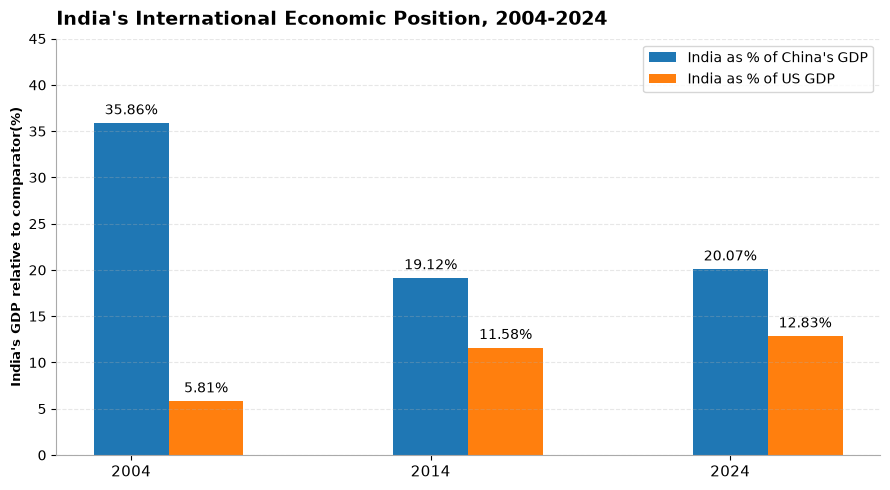

In [ ]:
import numpy as np

x = np.arange(len(df))
width = 0.25

# Create the figure and axes
fig, ax = plt.subplots(figsize=(9,5))

# Creating the grouped chart.
bar_chn = ax.bar(
    x,
    df['India_compared_to_China(GDP Current%)'],
    width,
    label="India as % of China's GDP"
)
bar_usa =ax.bar(
    x+0.25,
    df['India_compared_to_USA(GDP Current%)'],
    width,
    label='India as % of US GDP'
)

# Setting labels on top of bars
ax.bar_label(
    bar_chn,
    fmt='%.2f%%',
    padding=4
)

ax.bar_label(
    bar_usa,
    fmt='%.2f%%',
    padding=4
)


# titles and labels:
ax.set_title("India's International Economic Position, 2004-2024", fontsize=14, fontweight='bold', loc='left', pad=10)
ax.set_ylabel("India's GDP relative to comparator(%)", fontsize=9, fontweight='bold')
ax.set_ylim(0, 45)

# x-axis
ax.set_xticks(x)
ax.set_xticklabels(df['Year'], fontsize=11)

# removing the spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['bottom'].set_color('#aaaaaa')

# Grid
ax.grid(axis='y', linestyle='--', alpha=0.3)

ax.legend()

plt.tight_layout()
plt.show()


In [24]:
print(ind_gdp_current)
print(usa_gdp_current)

{2004: 0.71, 2014: 2.04, 2024: 3.76}
{2004: 12.22, 2014: 17.61, 2024: 29.3}
